In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
df = pd.read_csv("data.csv")
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [3]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [4]:
df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [5]:
strings = list(df.dtypes[df.dtypes == 'object'].index)

for col in strings:
    df[col] = df[col].str.lower().str.replace(' ', '_')

In [6]:
df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


In [7]:
df.dtypes

make                  object
model                 object
year                   int64
engine_fuel_type      object
engine_hp            float64
engine_cylinders     float64
transmission_type     object
driven_wheels         object
number_of_doors      float64
market_category       object
vehicle_size          object
vehicle_style         object
highway_mpg            int64
city_mpg               int64
popularity             int64
msrp                   int64
dtype: object

In [8]:
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

make
['bmw' 'audi' 'fiat' 'mercedes-benz' 'chrysler']
48

model
['1_series_m' '1_series' '100' '124_spider' '190-class']
914

year
[2011 2012 2013 1992 1993]
28

engine_fuel_type
['premium_unleaded_(required)' 'regular_unleaded'
 'premium_unleaded_(recommended)' 'flex-fuel_(unleaded/e85)' 'diesel']
10

engine_hp
[335. 300. 230. 320. 172.]
356

engine_cylinders
[ 6.  4.  5.  8. 12.]
9

transmission_type
['manual' 'automatic' 'automated_manual' 'direct_drive' 'unknown']
5

driven_wheels
['rear_wheel_drive' 'front_wheel_drive' 'all_wheel_drive'
 'four_wheel_drive']
4

number_of_doors
[ 2.  4.  3. nan]
3

market_category
['factory_tuner,luxury,high-performance' 'luxury,performance'
 'luxury,high-performance' 'luxury' 'performance']
71

vehicle_size
['compact' 'midsize' 'large']
3

vehicle_style
['coupe' 'convertible' 'sedan' 'wagon' '4dr_hatchback']
16

highway_mpg
[26 28 27 25 24]
59

city_mpg
[19 20 18 17 16]
69

popularity
[3916 3105  819  617 1013]
48

msrp
[46135 40650 36350 29450 345

<Axes: xlabel='msrp', ylabel='Count'>

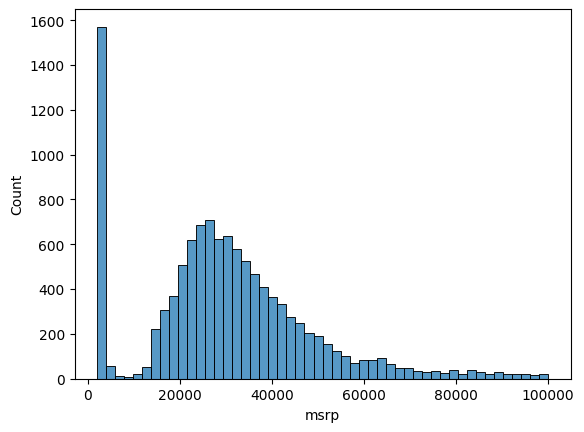

In [9]:
sns.histplot(df.msrp[df.msrp<100000], bins = 50)

In [10]:
price_logs = np.log1p(df.msrp)
price_logs

0        10.739349
1        10.612779
2        10.500977
3        10.290483
4        10.448744
           ...    
11909    10.739024
11910    10.945018
11911    10.832122
11912    10.838031
11913    10.274913
Name: msrp, Length: 11914, dtype: float64

<Axes: xlabel='msrp', ylabel='Count'>

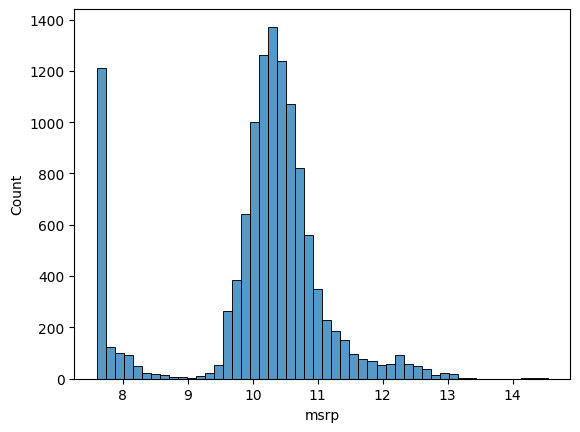

In [11]:
sns.histplot(price_logs, bins = 50)

In [12]:
df.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

In [13]:
n = len(df)
n_val = int(n*0.2)
n_test = int(n*0.2)
n_train = n - n_val - n_test
n_val, n_test, n_train

(2382, 2382, 7150)

In [14]:
df_train  = df.iloc[n_train:]
df_val = df.iloc[n_train:n_train+n_val]
df_test = df.iloc[n_train+n_val:]


In [15]:
df_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
7150,lincoln,navigator,2015,regular_unleaded,365.0,6.0,automatic,rear_wheel_drive,4.0,luxury,large,4dr_suv,20,15,61,63645
7151,lincoln,navigator,2016,regular_unleaded,380.0,6.0,automatic,rear_wheel_drive,4.0,luxury,large,4dr_suv,22,16,61,63195
7152,lincoln,navigator,2016,regular_unleaded,380.0,6.0,automatic,four_wheel_drive,4.0,luxury,large,4dr_suv,19,15,61,76650
7153,lincoln,navigator,2016,regular_unleaded,380.0,6.0,automatic,four_wheel_drive,4.0,luxury,large,4dr_suv,19,15,61,69135
7154,lincoln,navigator,2016,regular_unleaded,380.0,6.0,automatic,rear_wheel_drive,4.0,luxury,large,4dr_suv,20,15,61,65560
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11909,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,46120
11910,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,56670
11911,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,50620
11912,acura,zdx,2013,premium_unleaded_(recommended),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,50920


In [16]:
idx = np.arange(n)
idx

array([    0,     1,     2, ..., 11911, 11912, 11913], shape=(11914,))

In [17]:
np.random.seed(2)
np.random.shuffle(idx)

In [18]:
idx[n_train:]

array([2779, 3708, 4794, ..., 6637, 2575, 7336], shape=(4764,))

In [20]:
df_train  = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train+n_val]]
df_test = df.iloc[idx[n_train+n_val:]]

In [21]:
df_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
2735,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385,14410
6720,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031,19685
5878,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640,19795
11190,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873,2000
4554,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657,56260
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
434,bmw,4_series,2015,premium_unleaded_(required),300.0,6.0,automatic,rear_wheel_drive,2.0,"luxury,performance",midsize,convertible,31,20,3916,54900
1902,volkswagen,beetle,2015,premium_unleaded_(recommended),210.0,4.0,automated_manual,front_wheel_drive,2.0,"hatchback,performance",compact,2dr_hatchback,30,24,873,29215
9334,gmc,sierra_1500,2015,flex-fuel_(unleaded/e85),285.0,6.0,automatic,four_wheel_drive,4.0,flex_fuel,large,extended_cab_pickup,22,17,549,34675
5284,rolls-royce,ghost,2014,premium_unleaded_(required),563.0,12.0,automatic,rear_wheel_drive,4.0,"exotic,luxury,performance",large,sedan,21,13,86,303300


In [22]:
len(df_train), len(df_test), len(df_val)

(7150, 2382, 2382)

In [23]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_test

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,gmc,vandura,1994,regular_unleaded,165.0,6.0,automatic,rear_wheel_drive,3.0,NaN,compact,cargo_van,20,15,549,2000
1,mercedes-benz,600-class,1993,regular_unleaded,389.0,12.0,automatic,rear_wheel_drive,2.0,luxury,large,coupe,15,11,617,3211
2,toyota,venza,2013,regular_unleaded,268.0,6.0,automatic,all_wheel_drive,4.0,"crossover,performance",midsize,wagon,25,18,2031,31120
3,volvo,740,1992,regular_unleaded,114.0,4.0,automatic,rear_wheel_drive,4.0,luxury,midsize,sedan,26,18,870,2000
4,ford,crown_victoria,2010,flex-fuel_(unleaded/e85),224.0,8.0,automatic,rear_wheel_drive,4.0,flex_fuel,large,sedan,24,16,5657,29905
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2377,chevrolet,chevy_van,1998,regular_unleaded,200.0,6.0,automatic,rear_wheel_drive,3.0,NaN,midsize,cargo_van,18,13,1385,2052
2378,subaru,xv_crosstrek,2014,regular_unleaded,160.0,4.0,automatic,all_wheel_drive,4.0,"crossover,hybrid",compact,4dr_suv,33,29,640,25995
2379,dodge,magnum,2006,regular_unleaded,250.0,6.0,automatic,all_wheel_drive,4.0,NaN,large,wagon,22,15,1851,29100
2380,honda,civic,2016,regular_unleaded,174.0,4.0,automatic,front_wheel_drive,4.0,NaN,midsize,sedan,42,31,2202,22200


In [24]:
y_train = np.log1p(df_train.msrp.values)
y_val = np.log1p(df_val.msrp.values)
y_test = np.log1p(df_test.msrp.values)

In [25]:
del df_train['msrp']
del df_test['msrp']
del df_val['msrp']

In [26]:
len(y_train)

7150

In [27]:
y_val

array([10.19936098, 10.90872279,  9.72770457, ..., 11.21756062,
        9.77542688, 10.1924563 ], shape=(2382,))

In [28]:
df_train.iloc[10]

make                                 rolls-royce
model                     phantom_drophead_coupe
year                                        2015
engine_fuel_type     premium_unleaded_(required)
engine_hp                                  453.0
engine_cylinders                            12.0
transmission_type                      automatic
driven_wheels                   rear_wheel_drive
number_of_doors                              2.0
market_category        exotic,luxury,performance
vehicle_size                               large
vehicle_style                        convertible
highway_mpg                                   19
city_mpg                                      11
popularity                                    86
Name: 10, dtype: object

In [29]:
xi = [453, 11, 86]
w0 = 7.17
w = [0.01, 0.04, 0.002]

In [39]:
def linear_regression(xi):
    n = len(xi)
    pred = w0
    for j in range(n):
        pred = pred + w[j] * xi[j]
    return pred
    

In [40]:
result = linear_regression(xi)
result

12.312

In [41]:
np.expm1(result)

np.float64(222347.2221101062)

Linear Regression with Vector Multiplication

In [42]:
def dot(xi, w):
    n = len(xi)

    res = 0.0
    for j in range(n):
        res = res + xi[j] * w[j]
    return res
    

In [43]:
def linear_regression_vector(xi):
    return w0 + dot(xi, w) 
    

In [46]:
w_new = [w0] + w

In [47]:
def linear_regression_vector(xi):
    xi = [1] + xi
    return dot(xi, w_new) 
    

In [48]:
linear_regression_vector(xi)

12.312

In [49]:
xi = [453, 11, 86]
w0 = 7.17
w = [0.01, 0.04, 0.002]
w_new = [w0] + w

In [50]:
x1 = [1, 148, 24,1385]
x2 = [1, 132, 25,2031]
x10 = [1, 453, 11, 86]
x = [x1, x2, x10]
x = np.array(x)

In [51]:
def linear_regression(x):
    return x.dot(w_new)

In [52]:
linear_regression(x)

array([12.38 , 13.552, 12.312])

Training A Linear Regression Model

In [53]:
x = [ [148, 24,1385],
      [132, 25,2031],
      [453, 11, 86],
      [158, 24,185],
      [172, 25,201],
      [413, 11, 86],
      [38, 54,185],
      [142, 25,431],
      [453, 31, 86],
    ]

x = np.array(x)
x

array([[ 148,   24, 1385],
       [ 132,   25, 2031],
       [ 453,   11,   86],
       [ 158,   24,  185],
       [ 172,   25,  201],
       [ 413,   11,   86],
       [  38,   54,  185],
       [ 142,   25,  431],
       [ 453,   31,   86]])

In [54]:
y = [10000, 20000, 10050, 25000, 10000, 20000, 15000, 25000, 12000]

In [55]:
def train_linear_regression(x, y):
    ones = np.ones(x.shape[0])
    x = np.column_stack([ones, x])
    xTx = x.T.dot(x)
    xTx_inv = np.linalg.inv(xTx)
    w_full = xTx_inv.dot(x.T).dot(y)

    return w_full[0], w_full[1:]



In [56]:
train_linear_regression(x,y)

(np.float64(29402.281127275462),
 array([ -26.27891595, -227.79566084,   -2.08624774]))

Car Price Baseline Model

In [57]:
df_train.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity'],
      dtype='object')

In [58]:
base = ['engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity' ]

In [59]:
y_train

array([ 9.57574708,  9.887663  ,  9.89323518, ..., 10.45380308,
       12.62248099, 10.54061978], shape=(7150,))

In [62]:
x_train = df_train[base].fillna(0).values

In [63]:
w0, w = train_linear_regression(x_train, y_train)

In [64]:
y_pred = w0 + x_train.dot(w)

<Axes: ylabel='Count'>

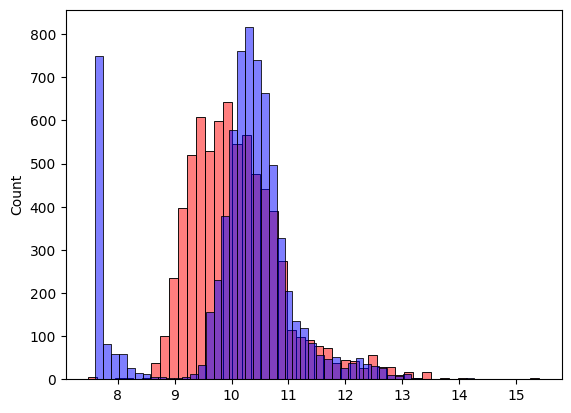

In [66]:
sns.histplot(y_pred, color = 'red', alpha =  0.5, bins = 50)
sns.histplot(y_train, color = 'blue',alpha =  0.5, bins = 50)

RMSE

In [68]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [69]:
rmse(y_train, y_pred)


np.float64(0.7554192603920132)

Validating The model

In [70]:
base = ['engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity' ]
x_train = df_train[base].fillna(0).values
w0, w = train_linear_regression(x_train, y_train)
y_pred = w0 + x_train.dot(w)

In [76]:
def prepare_x(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    x = df_num.values
    return x

In [77]:
x_train = prepare_x(df_train)
w0, w = train_linear_regression(x_train, y_train)
x_val = prepare_x(df_val)
y_pred = w0 + x_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.761653099130156)

Simple Feature Engineering

In [78]:
2017 - df_train.year

0        9
1        5
2        1
3       26
4        0
        ..
7145     2
7146     2
7147     2
7148     3
7149     0
Name: year, Length: 7150, dtype: int64

In [79]:
def prepare_x(df):
    df = df.copy()
    df['age'] = df.year
    features = base + ['age']
    df_num = df[features]
    df_num = df_num.fillna(0)
    x = df_num.values
    return x

In [80]:
x_train = prepare_x(df_train)


In [81]:
df_train.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity'],
      dtype='object')

In [84]:
x_train = prepare_x(df_train)
w0, w = train_linear_regression(x_train, y_train)
x_val = prepare_x(df_val)
y_pred = w0 + x_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.5172055461055305)

categorical Variables

In [73]:
for v in [2,3,4]:
    df_train['num_doors_%s'%v] = (df_train.number_of_doors ==v).astype('int')


In [85]:
def prepare_x(df):
    df = df.copy()
    features = base.copy()

    df['age'] =2017 - df.year
    features.append('age')
    
    for v in [2,3,4]:
        df['num_doors_%s'%v] = (df.number_of_doors ==v).astype('int')
        features.append('num_doors_%s'%v)
             


    df_num = df[features]
    df_num = df_num.fillna(0)
    x = df_num.values
    return x

In [86]:
x_train = prepare_x(df_train)
w0, w = train_linear_regression(x_train, y_train)
x_val = prepare_x(df_val)
y_pred = w0 + x_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.515799564150169)

In [90]:
makes = list(df.make.value_counts().head().index)
makes

['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge']

In [91]:
def prepare_x(df):
    df = df.copy()
    features = base.copy()

    df['age'] =2017 - df.year
    features.append('age')
    
    for v in [2,3,4]:
        df['num_doors_%s'%v] = (df.number_of_doors ==v).astype('int')
        features.append('num_doors_%s'%v)
    for v in makes:
        df['make_%s'%v] = (df.make ==v).astype('int')
        features.append('make_%s'%v)      


    df_num = df[features]
    df_num = df_num.fillna(0)
    x = df_num.values
    return x

In [92]:
x_train = prepare_x(df_train)
w0, w = train_linear_regression(x_train, y_train)
x_val = prepare_x(df_val)
y_pred = w0 + x_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.5076038849556795)

In [94]:
categorical_variables = ['make', 'engine_fuel_type', 'transmission_type', 'driven_wheels', 'market_category', 'vehicle_size', 'vehicle_style']

In [95]:
categories = {}
for c in categorical_variables:
    categories[c] = list(df[c].value_counts().head().index)

In [96]:
categories

{'make': ['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge'],
 'engine_fuel_type': ['regular_unleaded',
  'premium_unleaded_(required)',
  'premium_unleaded_(recommended)',
  'flex-fuel_(unleaded/e85)',
  'diesel'],
 'transmission_type': ['automatic',
  'manual',
  'automated_manual',
  'direct_drive',
  'unknown'],
 'driven_wheels': ['front_wheel_drive',
  'rear_wheel_drive',
  'all_wheel_drive',
  'four_wheel_drive'],
 'market_category': ['crossover',
  'flex_fuel',
  'luxury',
  'luxury,performance',
  'hatchback'],
 'vehicle_size': ['compact', 'midsize', 'large'],
 'vehicle_style': ['sedan',
  '4dr_suv',
  'coupe',
  'convertible',
  '4dr_hatchback']}

In [98]:
def prepare_x(df):
    df = df.copy()
    features = base.copy()

    df['age'] =2017 - df.year
    features.append('age')
    
    for v in [2,3,4]:
        df['num_doors_%s'%v] = (df.number_of_doors ==v).astype('int')
        features.append('num_doors_%s'%v)
    for c, values in categories.items():
        for v in values:
            df['%s_%s'%(c,v)] = (df[c] ==v).astype('int')
            features.append('%s_%s'%(c,v))      


    df_num = df[features]
    df_num = df_num.fillna(0)
    x = df_num.values
    return x

In [101]:
x_train = prepare_x(df_train)
w0, w = train_linear_regression(x_train, y_train)
x_val = prepare_x(df_val)
y_pred = w0 + x_val.dot(w)
rmse(y_val, y_pred)

np.float64(23.019020704791835)

Regularization

In [102]:
xTx = [
    [1, 2, 2],
    [2, 1, 1],
    [2, 1, 1]
]


In [103]:
xTx = xTx + 0.01*np.eye(3)
np.linalg.inv(xTx)

array([[ -0.33668906,   0.33501399,   0.33501399],
       [  0.33501399,  49.91540897, -50.08459103],
       [  0.33501399, -50.08459103,  49.91540897]])

In [104]:
def train_linear_regression_reg(x, y, r=0.001):
    ones = np.ones(x.shape[0])
    x = np.column_stack([ones, x])
    xTx = x.T.dot(x)
    xTx = xTx + r*np.eye(xTx.shape[0])

    xTx_inv = np.linalg.inv(xTx)
    w_full = xTx_inv.dot(x.T).dot(y)

    return w_full[0], w_full[1:]



In [105]:
x_train = prepare_x(df_train)
w0, w = train_linear_regression_reg(x_train, y_train, r= 0.01)
x_val = prepare_x(df_val)
y_pred = w0 + x_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.45652199012897743)

Tuning The Model

In [106]:
for r in [0, 0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10]:
    x_train = prepare_x(df_train)
    w0, w = train_linear_regression_reg(x_train, y_train, r= 0.01)
    x_val = prepare_x(df_val)
    y_pred = w0 + x_val.dot(w)
    score = rmse(y_val, y_pred)
    print(r, w0, score)
    

0 6.2766071476973995 0.45652199012897743
1e-05 6.2766071476973995 0.45652199012897743
0.0001 6.2766071476973995 0.45652199012897743
0.001 6.2766071476973995 0.45652199012897743
0.01 6.2766071476973995 0.45652199012897743
0.1 6.2766071476973995 0.45652199012897743
1 6.2766071476973995 0.45652199012897743
10 6.2766071476973995 0.45652199012897743


In [107]:
r = 0.001
x_train = prepare_x(df_train)
w0, w = train_linear_regression_reg(x_train, y_train, r= 0.01)
x_val = prepare_x(df_val)
y_pred = w0 + x_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.45652199012897743)

Using The Model


In [108]:
df_full_train = pd.concat([df_train, df_val])

In [109]:
df_full_train = df_full_train.reset_index(drop=True)

In [110]:
x_full_train = prepare_x(df_full_train)

In [111]:
x_full_train

array([[148.,   4.,  33., ...,   1.,   0.,   0.],
       [132.,   4.,  32., ...,   0.,   0.,   1.],
       [148.,   4.,  37., ...,   0.,   0.,   1.],
       ...,
       [332.,   8.,  23., ...,   0.,   0.,   0.],
       [148.,   4.,  34., ...,   0.,   0.,   0.],
       [290.,   6.,  25., ...,   0.,   0.,   0.]], shape=(9532, 41))

In [112]:
y_full_train = np.concatenate([y_train, y_val])

In [113]:
w0, w = train_linear_regression_reg(x_full_train, y_full_train, r= 0.001)


In [114]:
x_test = prepare_x(df_test)
y_pred = w0 + x_test.dot(w)
rmse(y_test, y_pred)

np.float64(0.45177493106214056)

In [115]:
car = df_test.iloc[20].to_dict()
car

{'make': 'toyota',
 'model': 'sienna',
 'year': 2015,
 'engine_fuel_type': 'regular_unleaded',
 'engine_hp': 266.0,
 'engine_cylinders': 6.0,
 'transmission_type': 'automatic',
 'driven_wheels': 'front_wheel_drive',
 'number_of_doors': 4.0,
 'market_category': nan,
 'vehicle_size': 'large',
 'vehicle_style': 'passenger_minivan',
 'highway_mpg': 25,
 'city_mpg': 18,
 'popularity': 2031}

In [116]:
df_small = pd.DataFrame([car])

In [117]:
x_small = prepare_x(df_small)

In [118]:
y_pred = w0 + x_small.dot(w)
y_pred = y_pred[0]
y_pred


np.float64(10.462651700289744)

In [119]:
np.expm1(y_pred)

np.float64(34983.19616272936)

In [120]:
y_test[20]

np.float64(10.463131911491967)

In [121]:
np.expm1(y_test[20])

np.float64(35000.00000000001)